# 00. ベースライン: 元の特徴量だけのLightGBM

**このノートブックの目的:** コンペで最初から与えられた元の特徴量だけでモデルを作り、以降の施策(特徴量・モデル・アンサンブル)を比べる土台のスコアを決める。

**結論:** 元の特徴量21個を単変量AUCの高い順に1つずつ足すと、20個目まで改善し、Genderだけは悪化した。Genderを除く**20個を土台**にした(OOF AUC 0.95846、Private LB 0.95910)。
このOOFは 01_EDA の6節でも使う。

## 準備

- ライブラリと、共通処理(`src/`の自分で書いたファイル)を読み込む。`src/features.py` はデータの読み込みと特徴量の作成、`src/modeling.py` はモデルの学習と評価。
- `DATA`: train.csv・test.csvを置き、予測も保存するフォルダ(`data/`)の場所。
- train・testを読み込み、目的変数 `satisfaction` を0/1の配列 `y` にする。

In [1]:
import sys  # Pythonの実行環境の設定(下の sys.path)に使う

sys.path.insert(0, "../src")  # src/ を読み込み先に加え、features.py・modeling.py を import できるようにする
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

import features
import modeling

plt.rcParams["font.family"] = "Meiryo"  # グラフの日本語ラベル用
DATA = features.DATA_DIR  # train.csv, test.csv, 予測も保存するフォルダのpathをDATA変数に入れる
train, test = features.load_train_and_test()  # train.csv, test.csv をtrain, test変数に入れる
y = train[features.TARGET].astype(int).values  # 目的変数 satisfaction(満足=True)を0/1の配列にする
print(f"train {len(train):,}行・test {len(test):,}行、満足率 {y.mean():.3f}")  # 行数と満足の割合を確かめる

train 699,635行・test 299,844行、満足率 0.444


## 1. 元の特徴量

#### ① 目的・仮説
- **確認したいこと:** 元の特徴量の型・値の種類・欠損・値の範囲。
- **なぜ必要か:** ベースラインに使う材料の全体像を、学習の前に把握しておくため。数値かカテゴリかで、モデルへの渡し方も変わる。
- **想定する結果:** 数値の特徴量とカテゴリの特徴量が混ざっている。欠損はほとんどない。

#### ② 検証方法
- **データ:** train(乗客1人が1行のアンケート結果)。目的変数は `satisfaction`(満足=1、不満=0)。元の特徴量は次の21個。

| 種類 | 特徴量 |
|---|---|
| 乗客 | Gender、Age、Customer Type |
| 旅行 | Type of Travel、Class、Flight Distance |
| 遅延 | Departure Delay in Minutes、Arrival Delay in Minutes |
| サービス評価(13項目) | Inflight wifi service、Departure/Arrival time convenient、Ease of Online booking、Gate location、Food and drink、Online boarding、Seat comfort、Inflight entertainment、On-board service、Leg room service、Baggage handling、Checkin service、Cleanliness |

- **方法:** 特徴量ごとに、型・値の種類・欠損の件数を数える。数値の特徴量は最小・最大、文字列(str型)の特徴量は値の一覧を出す。

#### ③ コード・実行結果

In [ ]:
original_features = features.ORIGINAL_FEATURES_BY_UNIVARIATE_AUC
rows = []
for name in original_features:
    x = train[name]
    numeric = pd.api.types.is_numeric_dtype(x)
    rows.append({"特徴量": name, "型": str(x.dtype), "値の種類": x.nunique(), "欠損": int(x.isna().sum()),
                 "最小": f"{x.min():g}" if numeric else "", "最大": f"{x.max():g}" if numeric else "",
                 "値": "" if numeric else " / ".join(sorted(x.dropna().unique()))})
print(f"元の特徴量 {len(original_features)}個、満足の割合 {y.mean():.3f}")
pd.DataFrame(rows).set_index("特徴量")

元の特徴量 21個、満足の割合 0.444


,型,値の種類,欠損,最小,最大,値
特徴量,,,,,,
Online boarding,int64,6,0,0,5,
Class,str,3,0,,,Business / Eco / Eco Plus
Inflight entertainment,int64,6,0,0,5,
Inflight wifi service,int64,6,0,0,5,
Seat comfort,int64,6,0,0,5,
Flight Distance,int64,3474,0,67,4983,
Type of Travel,str,2,0,,,Business travel / Personal Travel
On-board service,int64,6,0,0,5,
Cleanliness,int64,6,0,0,5,


#### ④ 考察・次のアクション
- **読み取れること:**
  - 数値は17個、文字列(str型)は4個(Gender・Customer Type・Type of Travel・Class。値は2〜3種類)。
  - サービス評価13項目は0〜5点(Baggage handlingだけ1〜5点)。Flight Distanceは67〜4,983で、値の種類が3,474と多い。遅延は0〜約490分。
  - 欠損はArrival Delay in Minutesの292行だけ。満足の割合は約44%。
- **想定との比較:** 想定どおりだった。
- **次のアクション:** 文字列の4個はcategory型に変換して渡す(02_preprocessing)。欠損は補完しない(LightGBMは欠損をそのまま扱える。02_preprocessing)。2節で、どの特徴量が単独で強いかを測り、足す順番を決める。

## 2. 特徴量ごとの単変量AUC(足す順番を決める)

#### ① 目的・仮説
- **確認したいこと:** 元の特徴量21個のうち、どれが単独で満足/不満を強く見分けられるか。
- **なぜ必要か:** 3節では、元の特徴量を強い順に1つずつ足して土台を決める。その順番を、同じ物差しで決めておく必要がある。
- **想定する結果:** サービス評価(特にOnline boarding)とClassが上位に来る。遅延・Genderは弱い。

#### ② 検証方法
- **データ:** train(699,635行)。
- **方法:** 特徴量1つだけで満足/不満を並べたときのAUCを、2通りで出す。1つは値の大小で並べる方法、もう1つは値ごとの満足率で並べる方法。2つの差が大きい特徴量は、値と満足率の関係がまっすぐでない(山型・U字型)。

#### ③ コード・実行結果

                                     raw   rate
feature                                        
Online boarding                    0.840  0.854
Class                                NaN  0.782
Inflight entertainment             0.745  0.745
Inflight wifi service              0.663  0.736
Seat comfort                       0.732  0.732
Flight Distance                    0.696  0.710
Type of Travel                       NaN  0.703
On-board service                   0.699  0.699
Cleanliness                        0.689  0.689
Leg room service                   0.688  0.688
Age                                0.624  0.685
Ease of Online booking             0.609  0.666
Baggage handling                   0.655  0.662
Checkin service                    0.636  0.636
Food and drink                     0.621  0.621
Gate location                      0.514  0.604
Customer Type                        NaN  0.586
Departure/Arrival time convenient  0.473  0.536
Arrival Delay in Minutes           0.484

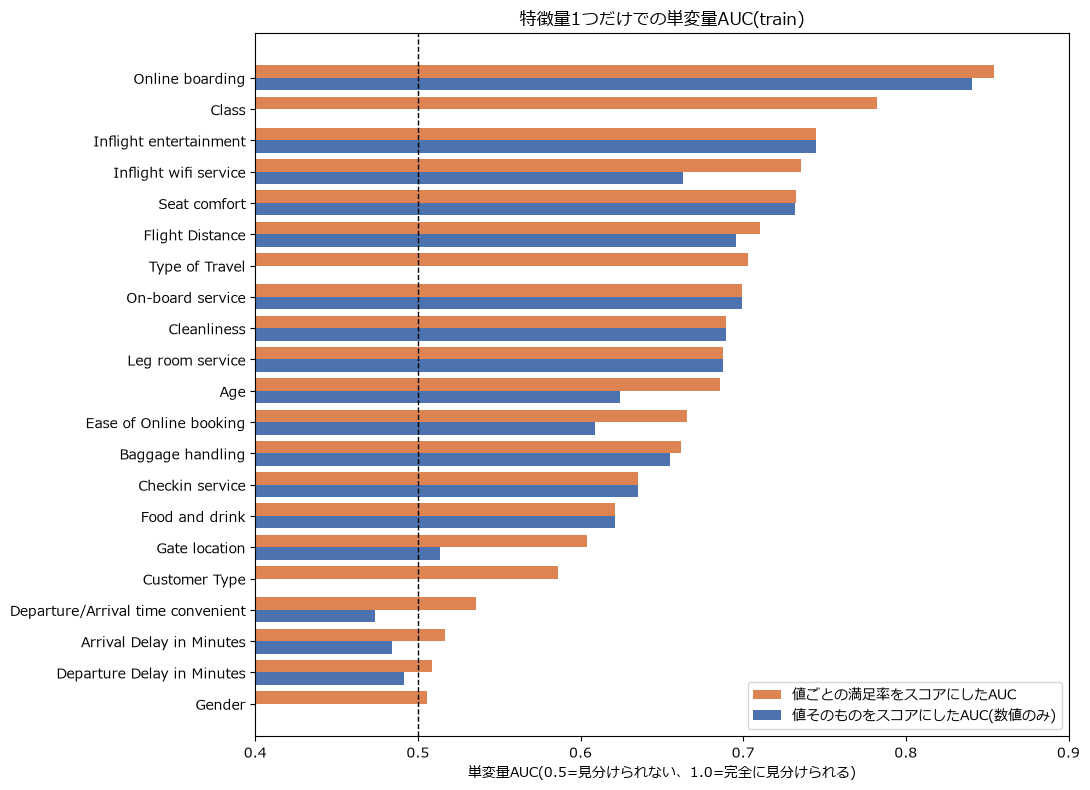

In [ ]:
# 単変量AUC: 特徴量1つだけを予測スコアとみなしたときに満足/不満をどれだけ並べ分けられるか
# raw  = 値そのものをスコアにする(「大きいほど満足」の一方向の関係だけを測る)
# rate = 値ごとの満足率をスコアにする(山型・U字型の関係やカテゴリ変数も測れる。連続値は50区間に分ける)
target = train[features.TARGET]
rows = []
for c in features.ORIGINAL_FEATURES_BY_UNIVARIATE_AUC:
    x = train[c]
    raw = roc_auc_score(target, x.fillna(-1)) if pd.api.types.is_numeric_dtype(x) else np.nan
    key = (pd.qcut(x, 50, duplicates="drop").astype(str) if x.nunique() > 50 else x.astype(str)).fillna("NA")
    rows.append((c, raw, roc_auc_score(target, target.groupby(key).transform("mean"))))
auc = pd.DataFrame(rows, columns=["feature", "raw", "rate"]).set_index("feature").sort_values("rate")
print(auc.sort_values("rate", ascending=False).round(3))

fig, ax = plt.subplots(figsize=(11, 8))
yy = np.arange(len(auc))
ax.barh(yy + 0.2, auc["rate"], height=0.4, color="#DD8452", label="値ごとの満足率をスコアにしたAUC")
ax.barh(yy - 0.2, auc["raw"], height=0.4, color="#4C72B0", label="値そのものをスコアにしたAUC(数値のみ)")
ax.axvline(0.5, color="k", ls="--", lw=1)
ax.set_yticks(yy, auc.index); ax.set_xlim(0.4, 0.9)
ax.set_xlabel("単変量AUC(0.5=見分けられない、1.0=完全に見分けられる)")
ax.set_title("特徴量1つだけでの単変量AUC(train)")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

#### ④ 考察・次のアクション
- **読み取れること:**
  - 上位はOnline boarding 0.854、Class 0.782、Inflight entertainment 0.745、Inflight wifi service 0.736。
  - 2通りのAUCの差が大きいのは、Gate location・Inflight wifi service・Age・Ease of Online booking。値と満足率の関係が山型・U字型の特徴量で、01_EDAの1・5節で詳しく見る。
- **想定との比較:** 想定どおり、サービス評価とClassが強かった。単独で弱い特徴量(遅延・Genderなど)も、組み合わせで効く可能性は残る(01_EDAの3節で見るように、Flight Distanceの単独の強さには客層の違いが含まれている)。
- **次のアクション:** 3節で、この単変量AUCの高い順(値ごとの満足率の方)に元の特徴量を足す。

## 3. 元の特徴量を1つずつ足して、効くものを選ぶ

#### ① 目的・仮説
- **確認したいこと:** 元の特徴量21個のうち、どれを土台に入れると効くか。
- **なぜ必要か:** 単独では弱くても、ほかと組み合わせると効く特徴量がある。単変量AUCだけでは決めず、実際に学習して1つずつ確かめる。
- **想定する結果:** 単変量AUCの高い順に足すと、伸びはだんだん小さくなる。単独で弱い特徴量(遅延・Genderなど)はほとんど効かない。

#### ② 検証方法
- **データ:** train。
- **方法:**
  - モデルはLightGBM(既定のハイパラ、学習率0.05)。欠損やカテゴリをそのまま扱え、70万行でも数分で学習できるので、比べる道具に向いている。
  - 評価は5分割の交差検証(StratifiedKFold、seed 42)。各行を、その行を学習していないモデルで予測した値(OOF)をつなげ、AUCで測る。木の本数は検証foldのAUCが100回伸びなくなったところで止める。
  - 2節の単変量AUC(値ごとの満足率)の高い順に、1個から21個まで足して21回学習する(1回あたり約3分)。

#### ③ コード・実行結果

In [3]:
results, X_test_baseline = [], None
for n in range(1, len(original_features) + 1):
    used = original_features[:n]
    X, X_test = features.build_train_and_test_tables(train, test, feature_names=[], base_features=used)
    oof, test_prediction = modeling.cross_validate_lightgbm(X, y, X_test=X_test if n == 20 else None, verbose=False)
    results.append({"個数": n, "足した特徴量": used[-1], "OOF AUC": roc_auc_score(y, oof)})
    if n == 20:
        np.save(DATA / "oof_lightgbm_baseline.npy", oof)
        baseline_test_prediction = test_prediction
    print(f"{n:2d}個 +{used[-1]}: OOF AUC {results[-1]['OOF AUC']:.6f}")
results = pd.DataFrame(results)
results["前からの伸び"] = results["OOF AUC"].diff()

 1個 +Online boarding: OOF AUC 0.853818


 2個 +Class: OOF AUC 0.902761


 3個 +Inflight entertainment: OOF AUC 0.920646


 4個 +Inflight wifi service: OOF AUC 0.944777


 5個 +Seat comfort: OOF AUC 0.946942


 6個 +Flight Distance: OOF AUC 0.948901


... (11 outputs left out)

18個 +Departure/Arrival time convenient: OOF AUC 0.958395


19個 +Arrival Delay in Minutes: OOF AUC 0.958432


20個 +Departure Delay in Minutes: OOF AUC 0.958459


21個 +Gender: OOF AUC 0.958440


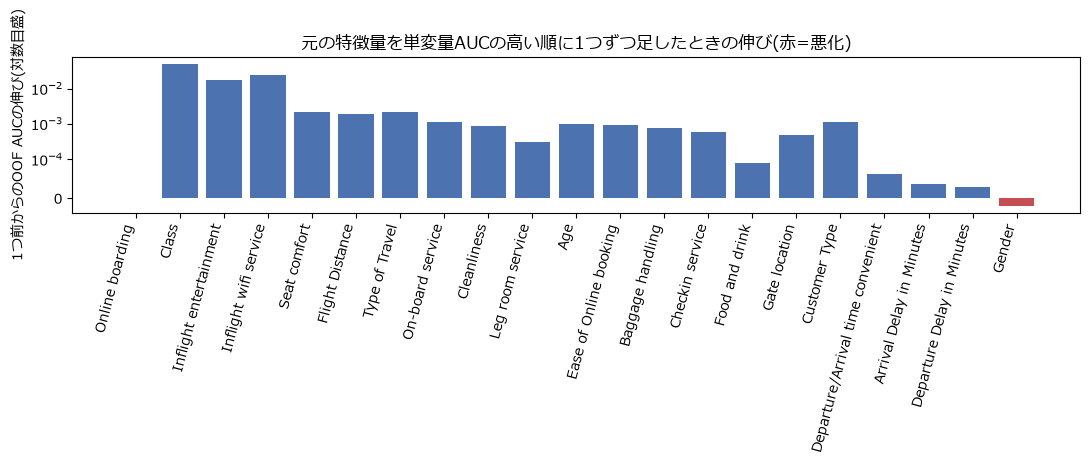

,個数,足した特徴量,OOF AUC,前からの伸び
0,1,Online boarding,0.853818,NaN
9,10,Leg room service,0.953355,0.000298
15,16,Gate location,0.957201,0.000483
16,17,Customer Type,0.958332,0.001131
19,20,Departure Delay in Minutes,0.958459,0.000028
20,21,Gender,0.958440,-0.000019


In [4]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(results["足した特徴量"], results["前からの伸び"].fillna(0), color=np.where(results["前からの伸び"] < 0, "#C44E52", "#4C72B0"))
ax.set_yscale("symlog", linthresh=1e-4)
ax.set_ylabel("1つ前からのOOF AUCの伸び(対数目盛)")
ax.set_title("元の特徴量を単変量AUCの高い順に1つずつ足したときの伸び(赤=悪化)")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()
results.iloc[[0, 9, 15, 16, 19, 20]].round(6)

#### ④ 考察・次のアクション
- **読み取れること:**
  - 20個目(Departure Delay in Minutes)まではすべて改善した。
  - 単独では弱いCustomer Type(単変量AUC 0.586)も、足すと+0.00113と大きく伸びた。客層ごとにサービス評価の効き方が違い、その切り替えに使われたと考えられる(01_EDAの4節で確かめた)。
  - Genderだけは−0.00002で、効かなかった。
- **想定との比較:** 伸びがだんだん小さくなり、Genderが効かなかったのは想定どおり。単独で弱いCustomer Typeが大きく効いたのは想定と違った。
- **次のアクション:**
  - Genderを外した20個を土台にする。
  - この判定はseed 42の1回だけで行った(採否の基準を設ける前だったため。基準は 03_feature_engineering の「採否の判定」)。Genderは、のちに特徴量を29個に増やした土台でも試し直したが、−0.000053で効かなかった(これも1seed)。

## 4. ベースラインの提出ファイル

#### ① 目的・仮説
- **確認したいこと:** 土台(20個)のモデルのスコアを、Kaggleのリーダーボード(LB)でも確かめる。
- **なぜ必要か:** 以降の施策を比べる出発点のスコアを、OOFとLBの両方で残しておくため。
- **想定する結果:** LBのスコアはOOF AUC(0.95846)に近い。

#### ② 検証方法
- **データ:** test。
- **方法:** 3節の20個のモデル(5つのfold)でtestを予測して平均し、提出ファイルにする。

#### ③ コード・実行結果

In [5]:
submission = pd.DataFrame({"id": test["id"], "satisfaction": baseline_test_prediction})
submission.to_csv(DATA / "submission_baseline.csv", index=False)
print(f"OOF AUC {results.loc[19, 'OOF AUC']:.5f} / 提出ファイル data/submission_baseline.csv({len(submission):,}行)")

OOF AUC 0.95846 / 提出ファイル data/submission_baseline.csv(299,844行)


#### ④ 考察・次のアクション
- **読み取れること:** Public LB 0.95817、Private LB 0.95910(上位76%)。
- **想定との比較:** 想定どおり、OOF AUC 0.95846に近かった。
- **次のアクション:** 01_EDAで、データの偏りから特徴量の着想を探す。

## Summary

| 決めたこと | 値 |
|---|---|
| 土台にする特徴量 | 元の特徴量21個からGenderを除いた20個 |
| 比べ方 | LightGBM・5分割(StratifiedKFold、seed 42)のOOF AUC |
| ベースラインのスコア | OOF AUC 0.95846 / Private LB 0.95910(上位76%) |